# Quick start: from AERONET-OC to the TOA signal

This tutorial simulates the top-of-atmosphere (TOA) reflectance seen by a satellite above an AERONET-OC station,
from the measurements of the station, in a few steps. It uses one day of the station *Acqua Alta Oceanographic
Tower* (AAOT, northern Adriatic Sea), 30 April 2025, a clear spring day:

1. read the AERONET-OC measurements (water reflectance, aerosols, gases, wind);
2. extend the water reflectance measured in a few bands to a full spectrum (invRrs);
3. choose the aerosol models that match the measured aerosol optical thickness;
4. simulate the TOA reflectance, with the sunglint (Sun reflected by the waves);
5. average it in 10 nm bands, as in the RadCalNet-OC products;
6. look at the sunglint flags and at the uncertainty of the simulation.

You need the full TOA look-up table (see {doc}`../installation`), the AERONET-OC database `aeronet_oc_db`
(see {doc}`radcalnet_oc_products`) and invRrs 1.4 (from GitHub, see {doc}`../installation`). To produce the files of a
whole site, see {doc}`radcalnet_oc_products`.

In [1]:
import logging

import matplotlib.pyplot as plt
rc = {"font.family": "serif",
      "mathtext.fontset": "stix"}
plt.rcParams.update(rc)
plt.rcParams["font.serif"] = ["Times New Roman"] + plt.rcParams["font.serif"]
plt.rcParams.update({'font.size': 16, 'axes.labelsize': 18})
# no warning when the Times New Roman font is not installed
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

import pandas as pd
import xarray as xr

import radcalnet_oc as radoc
from radcalnet_oc.aeronet_oc import aeronet_inputs
from radcalnet_oc.reconstruction import Reconstruction
from radcalnet_oc.products import INPUT_VARS, to_10nm

logging.getLogger().setLevel(logging.WARNING)   # show only the warnings
print(f'radcalnet_oc {radoc.__version__}')

radcalnet_oc 1.2.0


## 1. AERONET-OC measurements

`aeronet_inputs` reads the Level 2.0 data of the station for the chosen period and converts them into the
inputs of the simulation: gas columns, pressure, wind speed, aerosol optical thickness (AOT) and the
remote-sensing reflectance of the water `Rrs_Lwn` in the 11 bands of the radiometer.

In [2]:
records = aeronet_inputs('AAOT', 'lev20', start='2025-04-30', end='2025-04-30')
records[['sza_aeronet', 'aot550', 'ang_exp', 'wind', 'tcwv']].to_dataframe().round(3)

,sza_aeronet,aot550,ang_exp,wind,tcwv
time,,,,,
2025-04-30 09:17:17,38.033001,0.062,1.185,2.456,11.030
2025-04-30 09:22:02,37.442001,0.062,1.202,2.428,10.921
2025-04-30 09:26:48,36.866001,0.062,1.195,2.399,10.873
2025-04-30 09:41:30,35.210999,0.061,1.185,2.311,10.835
2025-04-30 09:46:16,34.716999,0.061,1.193,2.282,10.782
2025-04-30 09:51:03,34.241001,0.061,1.178,2.254,10.741
2025-04-30 10:17:10,32.077999,0.059,1.160,2.097,10.421
2025-04-30 10:21:55,31.771000,0.058,1.138,2.069,10.314
2025-04-30 10:26:42,31.490000,0.056,1.125,2.040,10.150


## 2. Hyperspectral water reflectance

The radiometer measures the water reflectance in a few bands only. A bio-optical model (invRrs) is fitted to
them and gives the full spectrum, here seen from nadir. The output keeps the version and the settings of invRrs
in its attributes.

In [3]:
hyp = Reconstruction().reconstruct(records.Rrs_Lwn, records.sza_aeronet, chl=records.chl)
hyp = hyp.where(hyp.success, drop=True)         # keep the successful fits
records = records.sel(time=hyp.time)
print(f"{hyp.sizes['time']} spectra, invRrs {hyp.attrs['invrrs_version']}")
pd.Series({k: v for k, v in hyp.attrs.items() if k.startswith('invrrs_')})

20 spectra, invRrs 1.4.0+g3b12a36


invrrs_version          1.4.0+g3b12a36
invrrs_model                  TwoModes
invrrs_ni_shape            atd_ext:0.5
invrrs_phyto_model     Ciotti2002_Sf03
invrrs_fluorescence               none
invrrs_sigma                      none
invrrs_max_nfev                    100
invrrs_vza                        40.0
invrrs_azi                        90.0
invrrs_max_sza                    80.0
invrrs_min_bands                     5
dtype: object

## 3. Input of the simulation and aerosol models

The input gathers, for each measurement (dimension `time`), the atmosphere, the water reflectance `Rrs`, the
solar zenith angle `sza` and the day of the year. The simulation is made for two viewing angles of the satellite:
nadir and 30° (relative azimuth 90°).

The aerosol is a mixture of standard models; their proportions are chosen to match the spectral shape of the
AOT measured by the station (`naot`).

In [4]:
input_db = records[INPUT_VARS + ['naot']].assign(Rrs=hyp.Rrs_nadir, sza=records.sza_aeronet,
                                                 day_of_year=records.time.dt.dayofyear)

vza = xr.DataArray([0., 30.], coords={'vza': [0., 30.]}, dims='vza')   # viewing zenith angles (deg)
azi = xr.DataArray([90.], coords={'azi': [90.]}, dims='azi')           # relative azimuth (deg)
process = radoc.Process(input_db, vza=vza, azi=azi)

aerosol = radoc.Aerosol(input_db.naot.dropna('wl_aeronet', how='all'), process.lut.naot_lut)
aerosol.process()
aerosol_combination = aerosol.model_db.aerosol_combination
aerosol_combination.mean('time').to_pandas().round(2)

model
ARCT_rh70    0.00
COAV_rh70    0.00
DESE_rh70    0.02
MACL_rh70    0.00
URBA_rh70    0.00
WASO_rh0     0.98
Name: aerosol_combination, dtype: float64

## 4. TOA simulation with the sunglint

`execute` runs the radiative transfer simulation at full spectral resolution (350-2500 nm). With
`sunglint='cm_iso_mix'`, it also computes the direct sunglint at the wind speed of the station: `Rtoa` is the
TOA reflectance without the direct sunglint, `Rglint` the sunglint and `Rtoa_glint` their sum, which is what the
satellite sees.

In [5]:
process.execute(aerosol_combination=aerosol_combination, sunglint='cm_iso_mix')
db = process.radcalnet_db
db[['Rtoa', 'Rglint', 'Rtoa_glint', 'glint_angle', 'glint_flags']]

<xarray.Dataset> Size: 21MB
Dimensions:      (time: 20, wl: 21532, vza: 2)
Coordinates:
  * time         (time) datetime64[ns] 160B 2025-04-30T09:17:17 ... 2025-04-3...
    aot_ref      (time) float64 160B 0.06229 0.06217 0.06171 ... 0.05451 0.05462
    sza          (time) float32 80B 38.03 37.44 36.87 ... 31.84 36.98 37.57
  * wl           (wl) float64 172kB 350.1 350.3 350.5 ... 2.499e+03 2.5e+03
  * vza          (vza) float64 16B 0.0 30.0
Data variables:
    Rtoa         (time, wl, vza) float64 7MB 0.2527 0.2633 ... 2.077e-05
    Rglint       (time, wl, vza) float64 7MB 0.0002771 0.0001155 ... 4.528e-05
    Rtoa_glint   (time, wl, vza) float64 7MB 0.253 0.2634 ... 6.605e-05
    glint_angle  (time, vza) float64 320B 38.03 46.99 37.44 ... 37.57 46.65
    glint_flags  (time, vza) uint8 40B 3 1 3 1 3 1 3 1 3 1 ... 1 3 1 3 1 3 1 3 1
Attributes:
    radcalnet_oc_version:  1.2.0+ge40cb2b
    o2_model:              lbl
    gas_coupling:          path_length
    gas_coupling_table:    gas_coupling_ppld.csv
    rrs_extension:         pure_water
    rayleigh_pressure:     1
    solar_database:        tsis
    default_wind:          2.0
    toa_lut:               toa_lut_opac_wind_v3.nc
    toa_lut_doi:           10.5281/zenodo.23394202

## 5. 10 nm bands and figure

`to_10nm` averages the spectra in bands of 10 nm every 10 nm, as in the RadCalNet-OC products (the first two
bands and the last one are slightly truncated by the range of the simulation, hence the warning). The figure shows
the first measurement of the day, close to the time of the Sentinel-2 overpass.

spectral response of the band(s) at [ 350.  360. 2490.] nm truncated by the wavelength range of the signal (350.109-2499.69 nm)


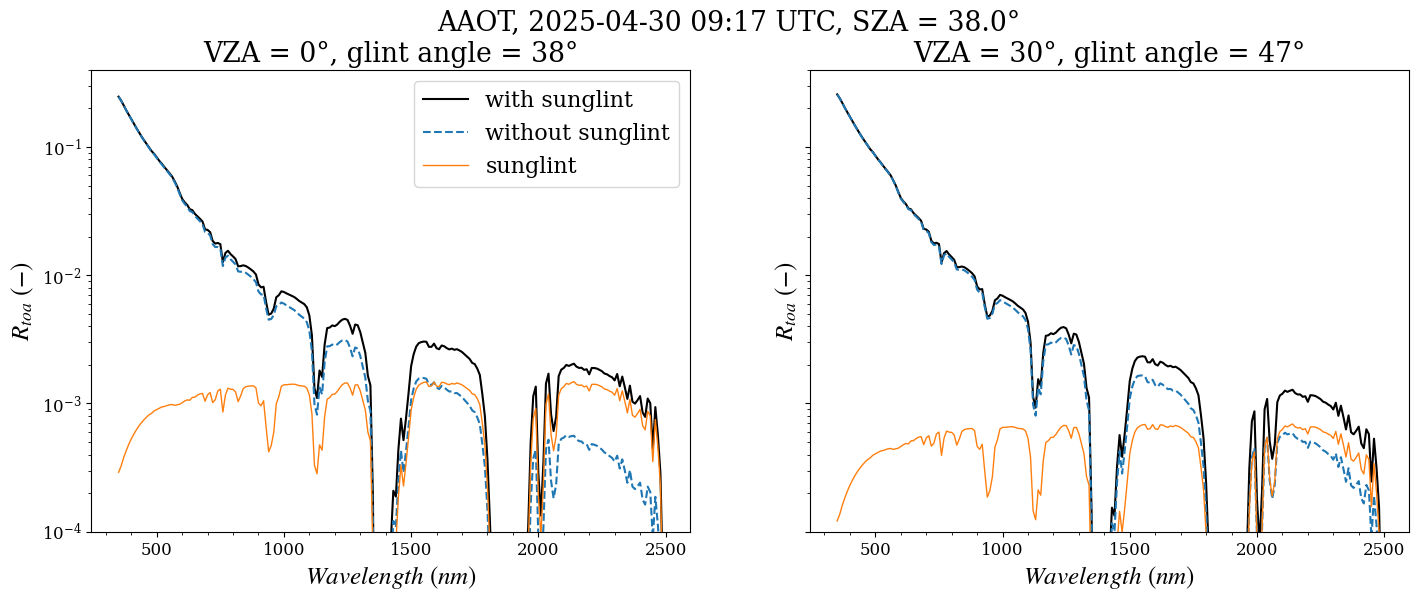

In [6]:
db10 = to_10nm(db)

t = db10.time.values[0]
fig, axs = plt.subplots(1, 2, figsize=(17, 6), sharey=True)
for ax, vza_ in zip(axs, [0., 30.]):
    d = db10.sel(time=t, vza=vza_)
    d.Rtoa_glint.plot(ax=ax, color='k', lw=1.5, label='with sunglint')
    d.Rtoa.plot(ax=ax, color='tab:blue', lw=1.5, ls='--', label='without sunglint')
    d.Rglint.plot(ax=ax, color='tab:orange', lw=1, label='sunglint')
    ax.set_yscale('log')
    ax.set_ylim(1e-4, 0.4)
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$R_{toa}\ (-)$')
    ax.set_title(f'VZA = {vza_:.0f}°, glint angle = {float(d.glint_angle):.0f}°')
    ax.minorticks_on()
axs[0].legend()
fig.suptitle(f"AAOT, {pd.Timestamp(t):%Y-%m-%d %H:%M} UTC, SZA = {float(db10.sza.sel(time=t)):.1f}°")
plt.show()

At nadir, the sensor looks at less than 40° from the direction of the specular reflection of the Sun
(glint angle): the sunglint is a large part of the signal in the near and shortwave infrared. At 30° off nadir
and 90° of azimuth, the glint angle is larger and the glint smaller.

## 6. Sunglint flags

`glint_flags` is a bitmask (`radcalnet_oc.GLINT_FLAGS`): sunglint above 1, 10 or 50 % of the TOA reflectance
at 865 nm (low, moderate, high) and near-specular geometry (glint angle < 30°). The simulation of the glint is
uncertain (sea surface slopes, wind): the measurements flagged moderate, high or near specular should not be
used for calibration.

In [7]:
def flag_names(value):
    return ', '.join(name.replace('glint_', '') for name, bit in radoc.GLINT_FLAGS.items() if int(value) & bit)


flags = db10.glint_flags.squeeze().to_pandas().map(flag_names)
flags.columns = [f'flags at VZA = {v:.0f}°' for v in flags.columns]
glint_angle = db10.glint_angle.squeeze().to_pandas().round(1)
glint_angle.columns = [f'glint angle at VZA = {v:.0f}°' for v in glint_angle.columns]
pd.concat([glint_angle, flags], axis=1)

,glint angle at VZA = 0°,glint angle at VZA = 30°,flags at VZA = 0°,flags at VZA = 30°
time,,,,
2025-04-30 09:17:17,38.0,47.0,"low, moderate",low
2025-04-30 09:22:02,37.4,46.6,"low, moderate",low
2025-04-30 09:26:48,36.9,46.1,"low, moderate",low
2025-04-30 09:41:30,35.2,45.0,"low, moderate",low
2025-04-30 09:46:16,34.7,44.6,"low, moderate",low
2025-04-30 09:51:03,34.2,44.3,"low, moderate",low
2025-04-30 10:17:10,32.1,42.8,"low, moderate",low
2025-04-30 10:21:55,31.8,42.6,"low, moderate",low
2025-04-30 10:26:42,31.5,42.4,"low, moderate",low


## 7. Uncertainty budget

`uncertainty_budget` runs the simulation again with each input shifted by its uncertainty (AOT, gases, pressure,
wind, $R_{rs}$), and adds the uncertainty of the sunglint (`glint`) and the model uncertainty (`model`, the part
of the differences with Sentinel-2 that the other terms do not explain). The table gives each term in % of the
TOA reflectance (with sunglint), for the first measurement at 30° off nadir (low sunglint). The wind shifted
by -1.5 m s$^{-1}$ is below the range of the look-up table, hence the warnings.

In [8]:
budget = radoc.uncertainty_budget(process)

terms = [v for v in budget.data_vars if v.startswith('u_') and v != 'u_total_rel']
one = budget[terms + ['Rtoa_glint']].sel(time=t, vza=30.).sel(wl=[443, 490, 560, 665, 865], method='nearest')
table = pd.DataFrame({name[2:]: 100 * one[name] / one.Rtoa_glint for name in terms}, index=one.wl.round().astype(int))
table.index.name = 'wavelength (nm)'
table.round(2)

wind speed out of the range of the look-up table (0.5-16 m s-1): clipped for 11 value(s)


wind speed out of the range of the look-up table (0.5-16 m s-1): clipped for 11 value(s)


,aot550,tcwv,tco3,pressure,wind,Rrs,glint,model,total
wavelength (nm),,,,,,,,,
443,1.19,0.02,0.01,0.15,0.00,0.42,0.15,0.19,1.29
490,1.43,0.00,0.06,0.14,0.02,0.80,0.25,1.14,2.02
560,1.70,0.00,0.28,0.11,0.05,1.37,0.43,3.52,4.17
665,3.07,0.00,0.13,0.13,0.12,0.65,1.09,0.62,3.38
865,5.03,0.00,0.00,0.12,0.23,0.13,3.32,20.15,21.03


The aerosol optical thickness is the largest term at 443, 490 and 665 nm, the model term at 560 nm and at
865 nm, where the signal is small; in the shortwave infrared (not shown) the relative uncertainty is larger
still.

Next steps:

- {doc}`radcalnet_oc_products`: the RadCalNet-OC daily products of a whole site, in batch;
- {doc}`radcalnet_oc_aeronet_oc_toa`: the same chain with more detail (aerosol fit, gaseous absorption);
- {doc}`radcalnet_oc_toa_simulation`: the effect of each setting of the simulation.